# CPlink tutorial for CITE-seq data

Here, we provide a simplified and fast demonstration of **CPlink** on brain epileptic lesions CITE-seq data and bulk RNA-seq data that include both disease and healthy samples. The bulk RNA-seq data were obtained from [Gomes-Duarte et al.](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE186334), and the target data was obtained from [François et al](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE256068).

The processed data in matrix format also can be obtained from [here](https://drive.google.com/drive/folders/1qhYt5v34xhBgMQ3uJnr8Us6k7WjrhaPP?usp=sharing)

In [1]:
library(DESeq2)
library(Seurat)
library(ggplot2)
library(CPlink)
library(CelliD)
set.seed(2025)

载入需要的程辑包：S4Vectors

载入需要的程辑包：stats4

载入需要的程辑包：BiocGenerics


载入程辑包：‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min



载入程辑包：‘S4Vectors’


The following object is masked from ‘package:utils’:

    findMatches


The following objects are masked from ‘package:base’:

    expand.grid, I, unname


载入需要的程辑包：IRanges

载入需要的程辑包：GenomicRanges

载入需要的程辑包：GenomeInfoDb

载入需要的程辑包：SummarizedExperiment

载入需要的程辑包：MatrixGenerics

载入需要的程辑包：matrixStats


载入程辑包：‘MatrixGenerics’


The following objects are m

In [2]:
setwd("~/CITE/")

# Load preprocessed data

In [3]:
bulk_count <- readRDS("bulk_count.rds")
bulk_meta <- readRDS("bulk_meta.rds")
seurat_obj <- readRDS("sc_seurat.rds")

# Identifying phenotype-specific genes from bulk data and getting cell-cell similarity graph and data matrix from target

In [4]:
bulk_meta$phenotype <- relevel(bulk_meta$phenotype,ref='Control')
Phe_Genes <- runDESeq2(bulk_count, bulk_meta, design_formula = ~ phenotype, p.adj = 0.05)
GEs_mtx <- data.frame(markers=rownames(Phe_Genes[[2]]), logFC=Phe_Genes[[2]]$log2FoldChange)
rownames(GEs_mtx) <- rownames(Phe_Genes[[2]])

converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates: 62 workers

mean-dispersion relationship

final dispersion estimates, fitting model and testing: 62 workers

-- replacing outliers and refitting for 281 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



In [5]:
data_matrix <- as.matrix(GetAssayData(seurat_obj, assay = "RNA", slot = "data"))

nn <- seurat_obj@graphs$wsnn

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 14.5 GiB”


# Run CPlink

In [6]:
CPlink_out_mtx <- runCPlink(data_matrix, GEs_mtx, snn = nn, seed_ratio = NULL, restart_prob = NULL, 
                            sim_methods = "cosine", SigThreshold = 0.05)

Starting CPlink pipeline

Running MCA on phenotype-specific features

Computing Fuzzy Matrix



0.585 sec elapsed


Computing SVD



7.832 sec elapsed


Computing Coordinates



0.238 sec elapsed


Calculating initial phenotype association scores

Restart Probability: 0.05; Seeds Ratio: 0.99

Computing empirical p-values and assign CPlink+ / CPlink- labels

CPlink run completed successfully



# Attach CPlink results to Seurat meta.data

In [7]:
seurat_obj <- seurat_obj
seurat_obj@meta.data <- cbind(seurat_obj@meta.data, 
                                  cbind(CPlink_out_mtx[[1]], CPlink_out_mtx[[2]])[rownames(seurat_obj@meta.data),])

# Visualization

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


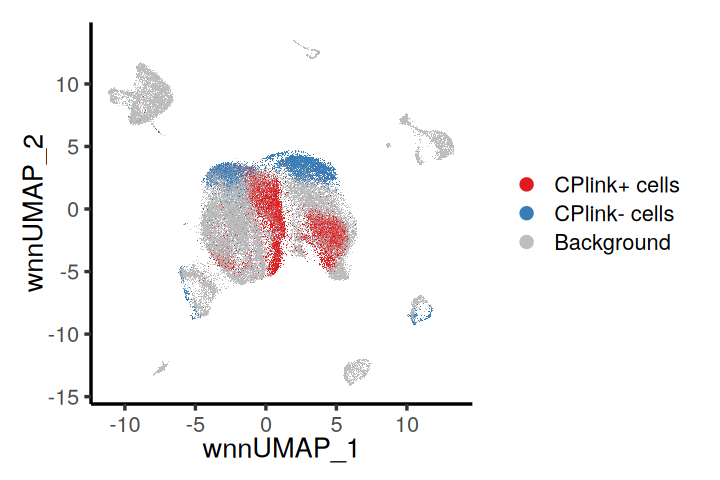

In [8]:
col_p <-c("#e11a1d", "#387db8", "grey" )
seurat_obj@meta.data$cellLabels <- factor(seurat_obj@meta.data$cellLabels, levels=c("CPlink+ cells", "CPlink- cells", "Background"))

options(repr.plot.width=6, repr.plot.height=4)
DimPlot(seurat_obj,reduction="wnn.umap",group.by=c("cellLabels"), #pt.size = 0.0000000001, 
               #label = F, 
               raster=TRUE,
       order=c("CPlink+ cells", "CPlink- cells", "Background"),
        cols = c("#e11a1d", "#387db8", "grey" ))+labs(title = NULL)+
scale_colour_discrete(breaks=c("CPlink+ cells", "CPlink- cells", "Background"), type= c("grey", "#387db8", "#e11a1d"))+

     theme_classic(base_size = 16, base_rect_size = 1.5)+
#guides(x = axis, y = axis) +
     theme(panel.grid = element_blank(), #axis.ticks = element_blank(),
          # legend.position = c(0.5,0.1),
           panel.border = element_blank(),
           #axis.text = element_blank(),
           #axis.title = element_blank(),
           plot.title = element_text( colour = "black"),
          legend.text = element_text( colour = "black"),
          
          #axis.line = element_line(linewidth = 0.5, arrow = arrow(type = "closed"))
          )

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


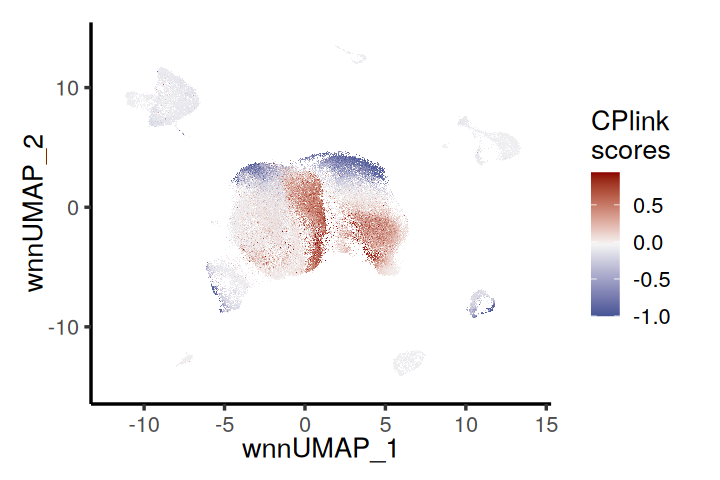

In [9]:
FeaturePlot(seurat_obj,reduction="wnn.umap",#split.by="disease",
            features = "CPlinkScore", raster=TRUE, label = FALSE) +
            scale_color_gradientn(colors = c("#475496", "#F5F5F5", "darkred"))+#c("lightblue", "white", "darkred")#"#4f5da7", "white", "#ea3433"
labs(title = NULL)+
     theme_classic(base_size = 16, base_rect_size = 1.5)+
#guides(x = axis, y = axis) +
     theme(panel.grid = element_blank(), #axis.ticks = element_blank(),#legend.position = "none",#c(0.2,0.5),
           panel.border = element_blank(),
           #axis.text = element_blank(),
          # axis.title = element_text(size = 0, hjust = 0, colour = "black"), 
           plot.title = element_text( hjust=0.5, colour = "black"),
          legend.text = element_text(colour = "black"),
          #legend.key.width = unit(15, "mm"), #调整图例color bar的宽高
         # legend.key.height = unit(5, "mm"),
         # axis.line = element_line(linewidth = 1, arrow = arrow(type = "closed"))
          ) +
  guides(color = guide_colorbar(title = "CPlink \nscores"))

In [10]:
sessionInfo()

R version 4.3.3 (2024-02-29)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Ubuntu 22.10

Matrix products: default
BLAS/LAPACK: /home/server/anaconda3/envs/CPlinkV2/lib/libopenblasp-r0.3.27.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=zh_CN.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=zh_CN.UTF-8        LC_COLLATE=zh_CN.UTF-8    
 [5] LC_MONETARY=zh_CN.UTF-8    LC_MESSAGES=zh_CN.UTF-8   
 [7] LC_PAPER=zh_CN.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=zh_CN.UTF-8 LC_IDENTIFICATION=C       

time zone: Asia/Shanghai
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] CelliD_1.10.1               SingleCellExperiment_1.22.0
 [3] CPlink_0.1.0                ggplot2_3.5.2              
 [5] SeuratObject_5.0.2          Seurat_4.4.0               
 [7] DESeq2_1.42.1              